# The adjoint method, by hand: aiming a thrown ball

**Question:** you throw a ball and want it to land on a target. How should you change the launch velocity (and,
later, a thrust profile with dozens of knobs) to get closer? You need $dJ/d\theta$, the gradient of the miss
distance with respect to every design parameter.

This notebook computes that gradient four ways and compares them:

| method | cost for $P$ parameters | memory |
|---|---|---|
| finite differences | $2P$ simulations | 1 state |
| **discrete adjoint** (hand-written) | 1 forward + 1 backward | all $N$ states |
| checkpointed adjoint | 1 forward + ~1 extra forward + 1 backward | $N/k + k$ states |
| continuous adjoint, state re-integrated backward | 1 forward + 1 backward | ~1 state, but can drift |

…plus `jax.grad`, which turns out to *be* the discrete adjoint, generated automatically. That is exactly what Allen
et al. (2022) use to optimise designs through a learned GNN simulator.

**Plan**

1. The simplest case (no drag): the adjoint is a transposed 4×4 matrix walked backwards.
2. Add drag: the Jacobian now depends on the state, so the backward pass needs the forward trajectory.
3. **Interactive:** slide through the backward sweep and watch the sensitivity flow from the target back to the launch.
4. Why adjoints win: cost vs number of parameters.
5. Memory: store everything vs checkpointing.
6. **Interactive:** the continuous adjoint and backward drift as drag increases.
7. **Interactive:** use the adjoint to optimise launch + thrust and hit the target.

In [1]:
import sys, time
sys.path.insert(0, "..")

import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as w

from src.ball import Problem, simulate, objective
from src import adjoint as A
from src.optimize import gradient_descent

plt.rcParams["figure.dpi"] = 100

def show_matrix(ax, M, title, rows=None, cols=None, vmax=None):
    M = np.atleast_2d(M); vmax = vmax or max(np.abs(M).max(), 1e-9)
    ax.imshow(M, cmap="RdBu_r", vmin=-vmax, vmax=vmax, aspect="auto")
    for (i, j), v in np.ndenumerate(M):
        ax.text(j, i, f"{v:.3g}", ha="center", va="center", fontsize=8, color="white" if abs(v) > 0.6 * vmax else "black")
    ax.set_xticks(range(M.shape[1])); ax.set_yticks(range(M.shape[0]))
    if cols: ax.set_xticklabels(cols)
    if rows: ax.set_yticklabels(rows)
    ax.set_title(title, fontsize=9)

## 1. The simplest case: no drag, two knobs

State $s = (x, y, v_x, v_y)$, gravity only, explicit Euler with $N = 200$ steps of $\Delta t = 0.01$ (so $T = 2$ s):

$$
x_{k+1} = x_k + \Delta t\, v_k, \qquad v_{k+1} = v_k + \Delta t\, g
$$

Design: the launch velocity $v_0$. Objective: $J = |x_N - x^\ast|^2$ with target $x^\ast = (8, 0)$.

**Step 1: write each step's Jacobian.** Here it is the same matrix at every step:

$$
\frac{\partial s_{k+1}}{\partial s_k} = \begin{bmatrix} I & \Delta t\, I \\ 0 & I \end{bmatrix}
$$

**Step 2: define the adjoint** $\lambda_k = \partial J / \partial s_k$ ("how much $J$ changes if I nudge the state at
step $k$"). At the end, $\lambda_N = (2(x_N - x^\ast),\ 0)$.

**Step 3: walk backwards with the transpose:** $\lambda_k = \left(\partial s_{k+1}/\partial s_k\right)^\top \lambda_{k+1}$.
After $N$ steps, $\partial J/\partial v_0 = \lambda_{v,0}$. That is the whole method.

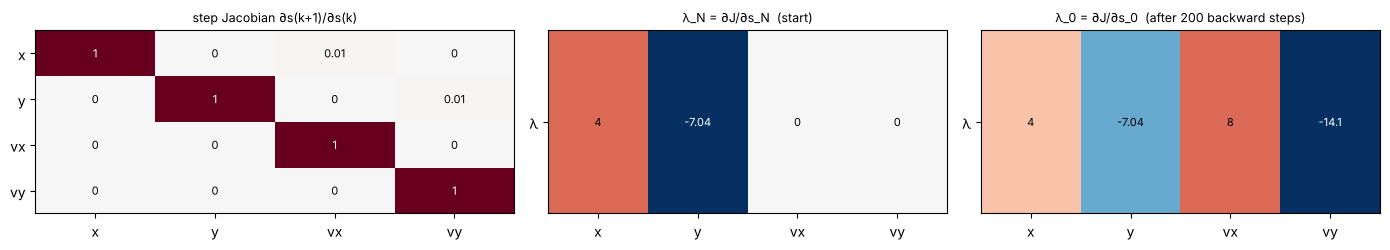

dJ/dv0  hand adjoint      : [  8.     -14.0876]
dJ/dv0  finite differences: [  7.99999999 -14.08759999]


dJ/dv0  jax.grad          : [  8.     -14.0876]
analytic (λ_x * T)        : [  8.     -14.0876]


In [2]:
p0 = Problem(drag=0.0)
v0 = np.array([5.0, 8.0]); U0 = np.zeros((p0.n_segments, 2))
dt = p0.dt
Jac = np.block([[np.eye(2), dt * np.eye(2)], [np.zeros((2, 2)), np.eye(2)]])

X, V = simulate(v0, U0, p0)
lam = np.r_[2 * (X[-1] - p0.target), 0, 0]
lam_N = lam.copy()
for k in range(p0.n_steps):
    lam = Jac.T @ lam          # the entire adjoint, for this linear case

fig, axes = plt.subplots(1, 3, figsize=(14, 2.6), gridspec_kw=dict(width_ratios=[1.2, 1, 1]))
labels = ["x", "y", "vx", "vy"]
show_matrix(axes[0], Jac, "step Jacobian ∂s(k+1)/∂s(k)", labels, labels)
show_matrix(axes[1], lam_N[None], "λ_N = ∂J/∂s_N  (start)", ["λ"], labels)
show_matrix(axes[2], lam[None], "λ_0 = ∂J/∂s_0  (after 200 backward steps)", ["λ"], labels)
plt.tight_layout(); plt.show()

print("dJ/dv0  hand adjoint      :", lam[2:])
print("dJ/dv0  finite differences:", A.finite_difference_gradient(v0, U0, p0)[0])
print("dJ/dv0  jax.grad          :", A.jax_gradient(v0, U0, p0)[0])
print("analytic (λ_x * T)        :", lam_N[:2] * p0.n_steps * dt)

Without drag, $\lambda_x$ never changes and $\lambda_v$ just accumulates $\Delta t\,\lambda_x$ each step, so
$\partial J/\partial v_0 = T \cdot 2(x_N - x^\ast)$: launching 1 m/s faster moves the landing point by $T$ metres.
All three methods agree.

## 2. Add drag: the Jacobian now depends on the state

With quadratic drag $\dot v = g + u - c\,|v|\,v$ the velocity block of the Jacobian becomes

$$
A_k = \frac{\partial v_{k+1}}{\partial v_k} = I - \Delta t\, c\left(|v_k|\, I + \frac{v_k v_k^\top}{|v_k|}\right)
$$

It contains $v_k$. To walk backwards you therefore need **every forward velocity**: you either store the whole
trajectory or recompute it. That is where an adjoint's memory cost comes from. The backward recurrence is now

$$
\lambda_{x,k} = \lambda_{x,k+1}, \qquad
\lambda_{v,k} = \Delta t\,\lambda_{x,k+1} + A_k^\top \lambda_{v,k+1}, \qquad
\frac{\partial J}{\partial u_k} = \Delta t\,\lambda_{v,k+1}
$$

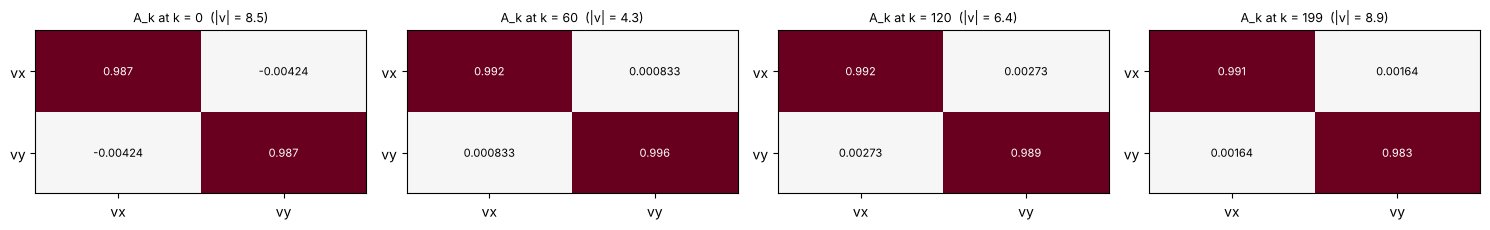

dJ/dv0   adjoint: [ -1.02056342 -13.12820193] 
         FD     : [ -1.02056344 -13.12820193] 
         jax    : [ -1.02056342 -13.12820193]
max |adjoint - jax| over all 22 parameters: 7.105427357601002e-15


In [3]:
prob = Problem(drag=0.1)
v0 = np.array([6.0, 6.0])
U = np.zeros((prob.n_segments, 2))
X, V = simulate(v0, U, prob)

fig, axes = plt.subplots(1, 4, figsize=(15, 2.4))
for ax, k in zip(axes, [0, 60, 120, 199]):
    show_matrix(ax, A.drag_jacobian(V[k], prob), f"A_k at k = {k}  (|v| = {np.linalg.norm(V[k]):.1f})", ["vx", "vy"], ["vx", "vy"], vmax=1)
plt.tight_layout(); plt.show()

gv_adj, gU_adj = A.discrete_adjoint_gradient(v0, U, prob)
gv_fd, gU_fd = A.finite_difference_gradient(v0, U, prob)
gv_ax, gU_ax = A.jax_gradient(v0, U, prob)
print("dJ/dv0   adjoint:", gv_adj, "\n         FD     :", gv_fd, "\n         jax    :", gv_ax)
print("max |adjoint - jax| over all 22 parameters:", max(np.abs(gv_adj - gv_ax).max(), np.abs(gU_adj - gU_ax).max()))

The hand-written adjoint and `jax.grad` agree to machine precision: **reverse-mode autodiff *is* the discrete
adjoint**, generated by the compiler instead of by hand. Finite differences agree to about 7 digits (truncation and
round-off).

## 3. Interactive: the backward sweep

Drag the slider from right ($k = N$, the end) to left ($k = 0$, the launch). The arrows on the trajectory show
$-\lambda_{v,k}$: **the direction in which nudging the ball's velocity at step $k$ would most reduce the miss**.
At the end they point straight at the target; going backwards in time they rotate and grow, because an early nudge
has more time to act and has to fight gravity and drag on the way. Notice that at the launch the arrow points
almost straight **up**, not toward the target: the ball falls short because it lands too early, so the most
effective fix is more vertical speed (more air time), which a human might not guess from "the target is to the
right".

> Sliders need a live Jupyter kernel (they don't render on GitHub). A static version follows.

In [4]:
_, _, H = A.discrete_adjoint_gradient(v0, U, prob, return_history=True)

def sweep(k=prob.n_steps):
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw=dict(width_ratios=[1.6, 1]))
    ax.plot(H["X"][:, 0], H["X"][:, 1], color="0.6", lw=1.5, label="trajectory")
    ax.plot(*prob.target, "r*", ms=15, label="target")
    idx = np.arange(k, prob.n_steps + 1, 10)
    s = 0.15
    ax.quiver(H["X"][idx, 0], H["X"][idx, 1], -H["LV"][idx, 0], -H["LV"][idx, 1],
              color="tab:blue", angles="xy", scale_units="xy", scale=1 / s, width=0.004)
    ax.plot(*H["X"][k], "o", color="tab:blue", ms=8)
    ax.set_aspect("equal"); ax.set_xlim(-1, 10); ax.set_ylim(-2, 4.5); ax.legend(loc="upper right")
    ax.set_title(f"backward sweep at k = {k}:  arrows = −λ_v (best velocity nudge)")
    t = np.arange(prob.n_steps + 1)
    for i, (lab, col) in enumerate([("λ_vx", "tab:blue"), ("λ_vy", "tab:orange")]):
        ax2.plot(t[k:], H["LV"][k:, i], color=col, label=lab)
        ax2.plot(t[:k + 1], H["LV"][:k + 1, i], color=col, alpha=0.15)
    ax2.axvline(k, color="k", lw=0.8); ax2.set_xlabel("step k"); ax2.legend(); ax2.set_title("adjoint so far (computed right → left)")
    plt.tight_layout(); plt.show()
    if k == 0:
        print("λ_v at k = 0 is the gradient dJ/dv0 =", H["LV"][0])

w.interact(sweep, k=w.IntSlider(min=0, max=prob.n_steps, step=5, value=prob.n_steps, description="step k",
                                continuous_update=False, layout=w.Layout(width="600px")));

interactive(children=(IntSlider(value=200, continuous_update=False, description='step k', layout=Layout(width=…

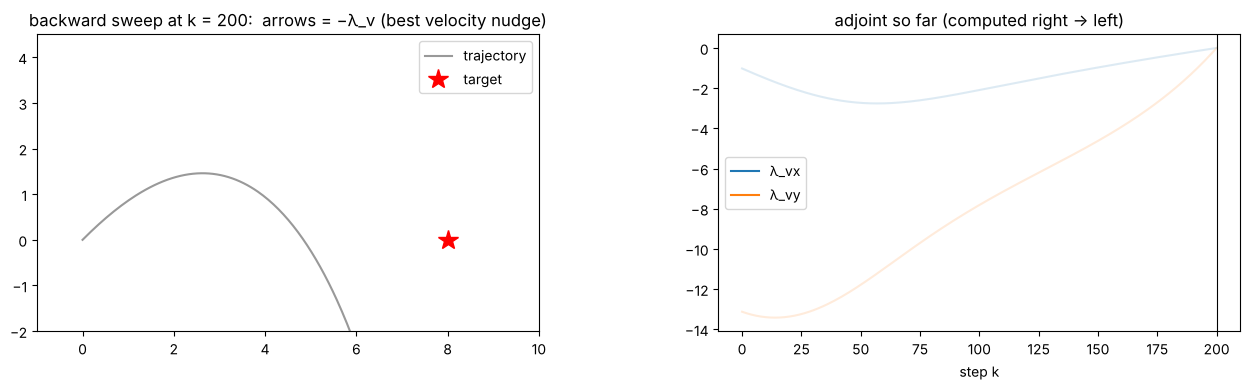

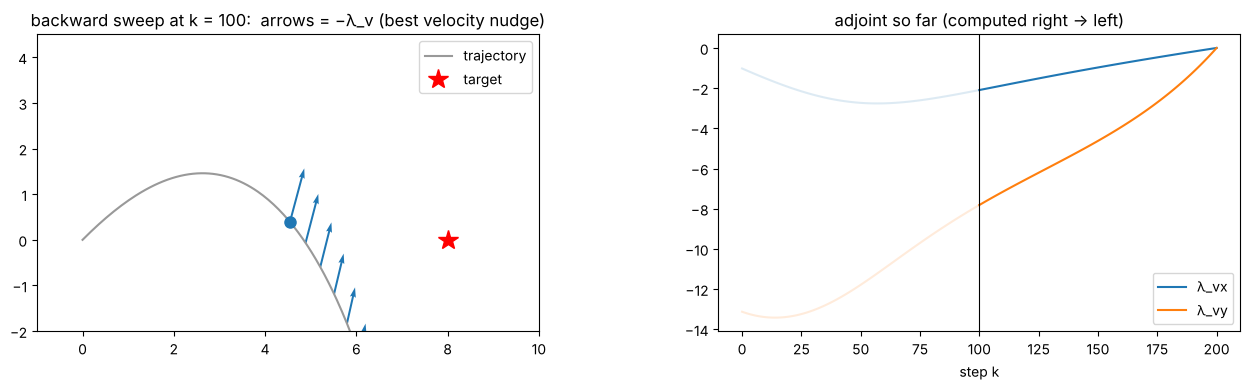

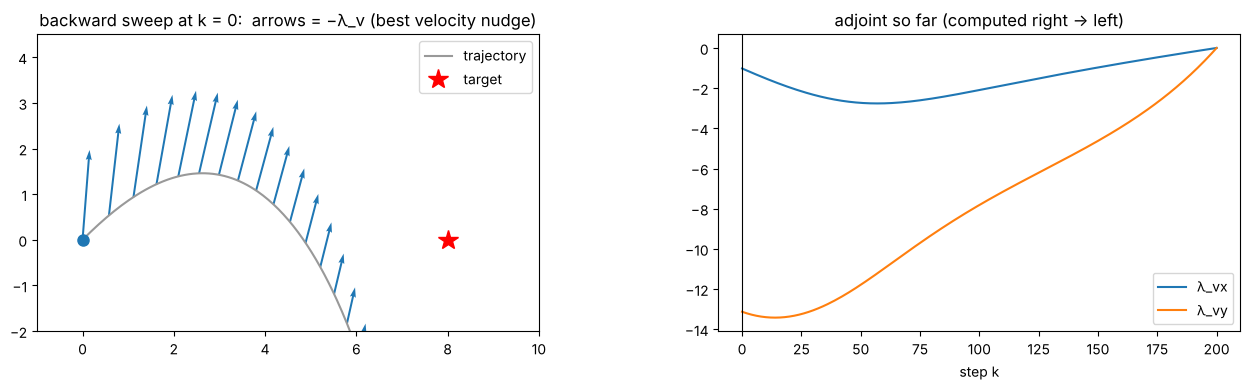

λ_v at k = 0 is the gradient dJ/dv0 = [ -1.02056342 -13.12820193]


In [5]:
for k in [prob.n_steps, 100, 0]:
    sweep(k)

## 4. Why adjoints win: cost vs number of parameters

Now give the ball a piecewise-constant thrust with $K$ segments, so there are $P = 2 + 2K$ design parameters.
Finite differences need two simulations per parameter; the adjoint needs one forward and one backward pass no
matter how many parameters there are. This is why the GNN design paper could optimise 625 landscape heights.

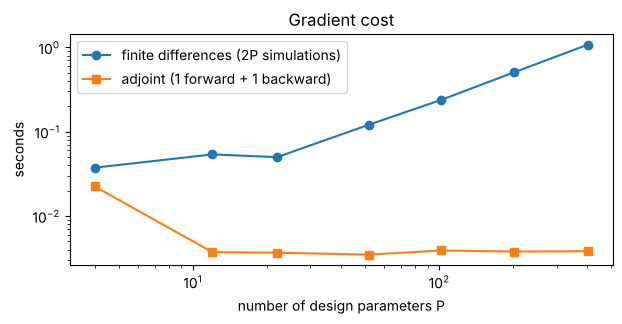

at P = 402: finite differences 1.08 s, adjoint 3.8 ms  (282× faster)


In [6]:
Ks, t_fd, t_adj = [1, 5, 10, 25, 50, 100, 200], [], []
for K in Ks:
    pk = Problem(drag=0.1, n_segments=K)
    Uk = np.zeros((K, 2))
    t = time.perf_counter(); A.finite_difference_gradient(v0, Uk, pk); t_fd.append(time.perf_counter() - t)
    t = time.perf_counter(); A.discrete_adjoint_gradient(v0, Uk, pk); t_adj.append(time.perf_counter() - t)
P = [2 + 2 * K for K in Ks]
fig, ax = plt.subplots(figsize=(7, 3))
ax.loglog(P, t_fd, "o-", label="finite differences (2P simulations)")
ax.loglog(P, t_adj, "s-", label="adjoint (1 forward + 1 backward)")
ax.set_xlabel("number of design parameters P"); ax.set_ylabel("seconds"); ax.legend(); ax.set_title("Gradient cost")
plt.show()
print(f"at P = {P[-1]}: finite differences {t_fd[-1]:.2f} s, adjoint {t_adj[-1]*1e3:.1f} ms  ({t_fd[-1]/t_adj[-1]:.0f}× faster)")

## 5. Memory: store everything vs checkpointing

The plain adjoint stores all $N + 1$ states. Checkpointing stores one state every $k$ steps, and during the backward
pass re-runs each $k$-step segment from its checkpoint. The gradient is **identical**; you pay with extra forward
steps. Allen et al. use this to backpropagate through long GNN rollouts.

In [7]:
U = np.random.default_rng(0).normal(size=(prob.n_segments, 2))
g_ref = A.discrete_adjoint_gradient(v0, U, prob)
print(f"{'checkpoint every':>16} | {'states stored':>13} | {'forward steps':>13} | max |grad - plain adjoint|")
print(f"{'(plain adjoint)':>16} | {prob.n_steps + 1:>13} | {prob.n_steps:>13} | 0")
for every in [5, 10, 14, 20, 50, 100]:
    gv, gU, st = A.checkpointed_adjoint_gradient(v0, U, prob, every)
    err = max(np.abs(gv - g_ref[0]).max(), np.abs(gU - g_ref[1]).max())
    print(f"{every:>16} | {st['stored_states']:>13} | {st['forward_steps']:>13} | {err:.1e}")
print("\nBest memory is near every ≈ √N ≈ 14: about 2√N states for about 2× the forward work.")

checkpoint every | states stored | forward steps | max |grad - plain adjoint|
 (plain adjoint) |           201 |           200 | 0
               5 |            46 |           360 | 0.0e+00
              10 |            31 |           380 | 0.0e+00
              14 |            29 |           385 | 0.0e+00
              20 |            31 |           390 | 0.0e+00
              50 |            55 |           396 | 0.0e+00
             100 |           103 |           398 | 0.0e+00

Best memory is near every ≈ √N ≈ 14: about 2√N states for about 2× the forward work.


## 6. Interactive: the continuous adjoint and backward drift

The continuous adjoint keeps **no** trajectory. It starts from the final state and integrates the state ODE
**backwards in time** alongside the adjoint ODE

$$
\dot\lambda_x = 0, \qquad \dot\lambda_v = -\lambda_x + c\left(|v|\,\lambda_v + \frac{v\,(v\cdot\lambda_v)}{|v|}\right)
$$

This is the trick that gives Neural ODEs (Week 5) constant memory. Its catch: drag removes energy going forward, so
**running it backwards amplifies every small error**. Slide the drag coefficient up and watch the reconstructed
trajectory (dashed) peel away from the true one, and the gradient error grow.

In [8]:
def drift(drag=0.1):
    pc = Problem(drag=drag)
    gv_c, _, Hc = A.continuous_adjoint_gradient(v0, np.zeros((pc.n_segments, 2)), pc, return_history=True)
    gv_d, _ = A.discrete_adjoint_gradient(v0, np.zeros((pc.n_segments, 2)), pc)
    fig, ax = plt.subplots(figsize=(10, 3.6))
    ax.plot(Hc["X"][:, 0], Hc["X"][:, 1], lw=2, label="true forward trajectory")
    ax.plot(Hc["Xb"][:, 0], Hc["Xb"][:, 1], "--", lw=2, label="re-integrated backward from x_N")
    ax.plot(0, 0, "ko", label="true launch point"); ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1)); ax.set_xlabel("x"); ax.set_ylabel("y")
    gap = np.linalg.norm(Hc["Xb"][0])
    rel = np.linalg.norm(gv_c - gv_d) / np.linalg.norm(gv_d)
    ax.set_title(f"drag c = {drag:.2f}:  reconstructed launch point is {gap:.3f} m off,  gradient error {100*rel:.1f}%")
    plt.tight_layout(); plt.show()

w.interact(drift, drag=w.FloatSlider(min=0.0, max=1.5, step=0.05, value=0.1, continuous_update=False,
                                     layout=w.Layout(width="500px")));

interactive(children=(FloatSlider(value=0.1, continuous_update=False, description='drag', layout=Layout(width=…

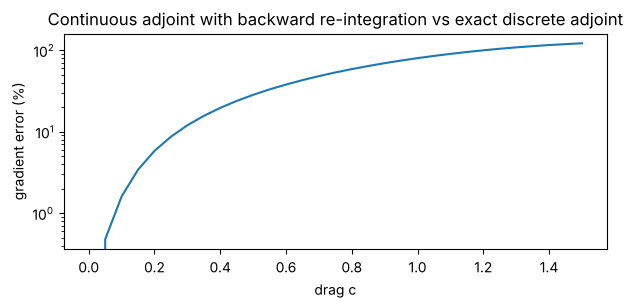

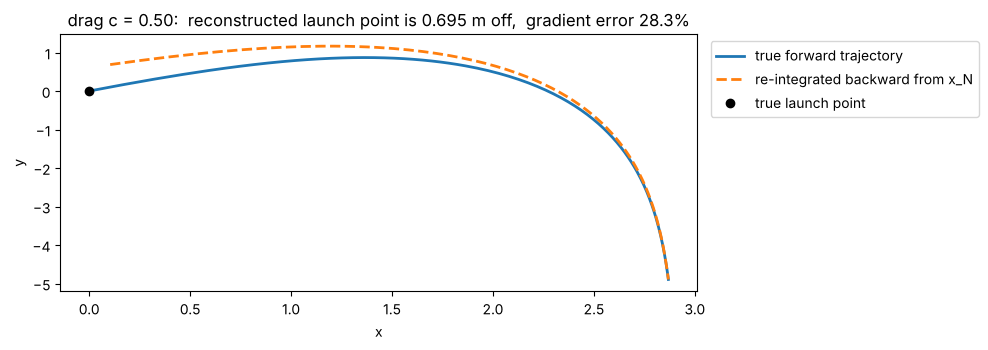

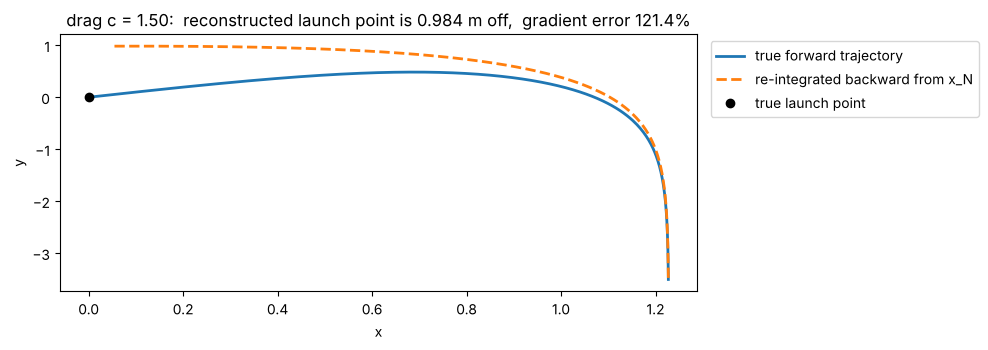

In [9]:
cs = np.linspace(0, 1.5, 31); errs = []
for c in cs:
    pc = Problem(drag=c); Z = np.zeros((pc.n_segments, 2))
    gc, _ = A.continuous_adjoint_gradient(v0, Z, pc); gd, _ = A.discrete_adjoint_gradient(v0, Z, pc)
    errs.append(np.linalg.norm(gc - gd) / np.linalg.norm(gd))
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.semilogy(cs, np.array(errs) * 100); ax.set_xlabel("drag c"); ax.set_ylabel("gradient error (%)")
ax.set_title("Continuous adjoint with backward re-integration vs exact discrete adjoint"); plt.show()
for c in [0.5, 1.5]:
    drift(c)

At $c = 0$ the gradient is exact: the adjoint equations don't involve the state at all, so it doesn't matter that
the reconstructed trajectory is slightly off. With drag, two errors appear. First, the adjoint now reads the state,
so drift in the backward re-integration feeds straight into the gradient. Second, the continuous adjoint
differentiates the ODE and then discretises, while the discrete adjoint differentiates the code you actually ran
("optimise-then-discretise" vs "discretise-then-optimise"), and the two stop agreeing once the dynamics are
nonlinear. For splashing, viscous fluids this is why people store or checkpoint instead.

## 7. Interactive: use the adjoint to hit the target

Gradient descent on all 22 parameters (launch velocity + 10 thrust segments), with each gradient from one adjoint
pass, starting from a throw that falls short. Slide through the iterations.

In [10]:
popt = Problem(drag=0.1, reg=0.05)
hist = gradient_descent(np.array([4.0, 6.0]), np.zeros((popt.n_segments, 2)), popt, n_iters=150, lr=0.02)

def opt_view(it=0):
    h = hist[it]
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw=dict(width_ratios=[1.6, 1]))
    for j in range(0, it, 10):
        ax.plot(hist[j]["X"][:, 0], hist[j]["X"][:, 1], color="0.85", lw=1)
    ax.plot(h["X"][:, 0], h["X"][:, 1], lw=2.5, label=f"iteration {it}")
    seg = np.linspace(0, popt.n_steps, popt.n_segments, endpoint=False).astype(int) + popt.n_steps // (2 * popt.n_segments)
    ax.quiver(h["X"][seg, 0], h["X"][seg, 1], h["U"][:, 0], h["U"][:, 1], color="tab:red", angles="xy",
              scale_units="xy", scale=1.5, width=0.004, label="thrust")
    ax.plot(*popt.target, "r*", ms=15, label="target"); ax.set_aspect("equal")
    ax.set_xlim(-1, 10); ax.set_ylim(-3, 6); ax.legend(loc="lower left")
    ax.set_title(f"v0 = ({h['v0'][0]:.2f}, {h['v0'][1]:.2f}),  miss = {np.linalg.norm(h['X'][-1] - popt.target):.3f} m")
    ax2.semilogy([x["J"] for x in hist], color="0.6"); ax2.plot(it, h["J"], "ro")
    ax2.set_xlabel("iteration"); ax2.set_title("objective J"); plt.tight_layout(); plt.show()

w.interact(opt_view, it=w.IntSlider(min=0, max=len(hist) - 1, value=0, description="iteration",
                                   continuous_update=False, layout=w.Layout(width="600px")));

interactive(children=(IntSlider(value=0, continuous_update=False, description='iteration', layout=Layout(width…

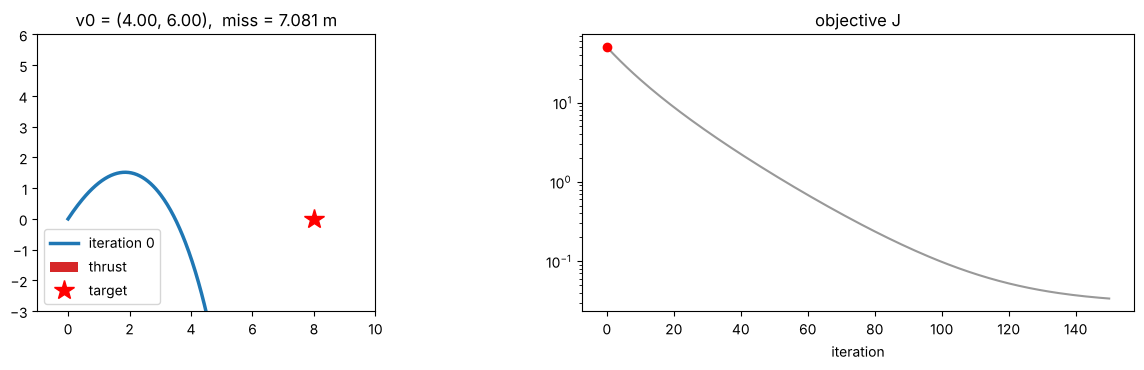

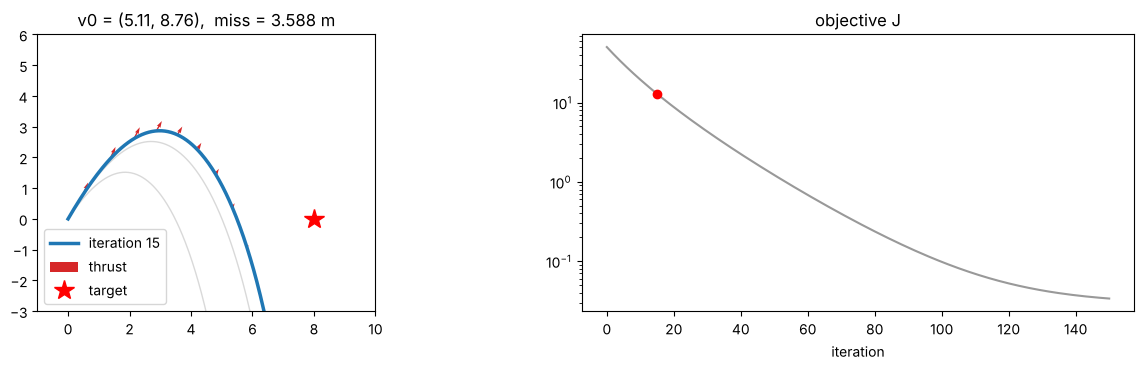

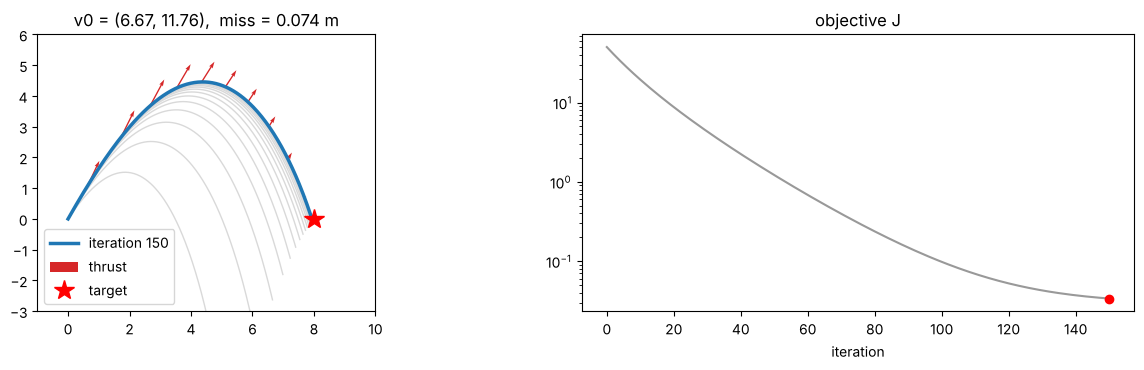

In [11]:
for it in [0, 15, len(hist) - 1]:
    opt_view(it)

## Takeaways, connected to the Week 6 papers

* **The adjoint is the chain rule run backwards** with transposed step Jacobians. One backward pass gives the
  gradient for every parameter at once, so it beats finite differences as soon as there are more than a handful of
  knobs.
* **Its memory cost comes from state-dependent Jacobians.** You store the trajectory, checkpoint it, or
  re-integrate it backwards and accept drift.
* **Writing it by hand means differentiating every operation of the solver.** Here that is one 2×2 matrix. In
  OpenFOAM it took the DAFoam project years.
* **`jax.grad` produced the same numbers automatically.** That is why Allen et al. (2022) can optimise designs
  through a GNN simulator: the network is built from operations JAX already knows how to differentiate, so its exact
  discrete adjoint comes for free. The catch is that it is the adjoint of the *learned* model, not of the real
  physics.